# GAN

In [1]:
import os
import json
import math
import torch
from torch import nn, optim
from torch.nn import functional as F
from torchvision import datasets
import torchvision.utils as vutils
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
print(torch.__version__, device)

2.11.0+cu128 cuda


In [2]:
BATCH_SIZE = 128
NOISE_DIM = 100
LABEL_DIM = 50
N_CLASSES = 10
LR = 2e-4
BETAS = (0.5, 0.999)
GAN_EPOCHS = 20
SHOW_INTERVAL = 5
LOG_INTERVAL = 200
CLF_EPOCHS = 3
DATASETS = {'mnist': datasets.MNIST, 'fashion': datasets.FashionMNIST, 'cifar10': datasets.CIFAR10}
CLASSES = {
    'mnist': [str(i) for i in range(10)],
    'fashion': ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot'],
    'cifar10': ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'],
}

In [3]:
def load_data(name, train=True):
    ds = DATASETS[name](root=f'./data_{name}', train=train, download=True)
    if name == 'cifar10':
        x = torch.tensor(ds.data).permute(0, 3, 1, 2)
        y = torch.tensor(ds.targets)
    else:
        x = ds.data.unsqueeze(1)
        y = ds.targets
    return (x.float() / 127.5 - 1).to(device), y.to(device)

def batches(x, y, batch_size, shuffle=True):
    n = len(x)
    idx = torch.randperm(n, device=x.device) if shuffle else torch.arange(n, device=x.device)
    for i in range(0, n, batch_size):
        j = idx[i:i + batch_size]
        yield x[j], y[j]

def to_img(x):
    return (x.clamp(-1, 1) + 1) / 2

def show_grid(imgs, title, nrow=10, path=None, size=6):
    grid = vutils.make_grid(to_img(imgs).cpu(), nrow=nrow, padding=2)
    plt.figure(figsize=(size, size))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis('off')
    if path:
        plt.savefig(path)
    plt.show()

In [4]:
class Classifier(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(4), nn.Flatten(),
            nn.Linear(64 * 16, 128), nn.ReLU(),
            nn.Linear(128, N_CLASSES),
        )
    def forward(self, x):
        return self.net(x)

def train_classifier(x, y, x_test, y_test, epochs=CLF_EPOCHS):
    clf = Classifier(x.size(1)).to(device)
    opt = optim.Adam(clf.parameters(), lr=1e-3)
    for epoch in range(epochs):
        clf.train()
        for xb, yb in batches(x, y, 256):
            loss = F.cross_entropy(clf(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
    clf.eval()
    with torch.no_grad():
        correct = sum((clf(xb).argmax(1) == yb).sum().item() for xb, yb in batches(x_test, y_test, 1000, shuffle=False))
    print(f'classifier test accuracy {correct / len(x_test):.3f}')
    return clf

@torch.no_grad()
def diversity(x, n=500):
    x = x[:n].flatten(1)
    d = torch.cdist(x, x)
    return (d.sum() / (len(x) * (len(x) - 1))).item()

@torch.no_grad()
def eval_samples(G, clf, conditional=False, n=2000):
    G.eval()
    clf.eval()
    z = torch.randn(n, NOISE_DIM, device=device)
    y = torch.arange(n, device=device) % N_CLASSES
    fake = G(z, y if conditional else None)
    probs = F.softmax(clf(fake), dim=1)
    pred = probs.argmax(1)
    stats = {
        'confidence': probs.max(1).values.mean().item(),
        'diversity': diversity(fake),
        'class_hist': (torch.bincount(pred, minlength=N_CLASSES).float() / n).tolist(),
    }
    if conditional:
        stats['label_acc'] = (pred == y).float().mean().item()
    return stats

def plot_class_hist(stats, title, classes):
    plt.figure(figsize=(8, 3))
    plt.bar(range(N_CLASSES), stats['class_hist'])
    plt.axhline(1 / N_CLASSES, color='r', linestyle='--', label='uniform')
    plt.xticks(range(N_CLASSES), classes, rotation=45)
    plt.ylabel('share of samples')
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Vanilla GAN

In [5]:
class Generator(nn.Module):
    def __init__(self, n_classes=0, ch=1):
        super().__init__()
        self.n_classes = n_classes
        if n_classes:
            self.embed = nn.Embedding(n_classes, LABEL_DIM)
        in_dim = NOISE_DIM + (LABEL_DIM if n_classes else 0)
        self.fc = nn.Sequential(nn.Linear(in_dim, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, ch, 4, 2, 1), nn.Tanh(),
        )
    def forward(self, z, y=None):
        if self.n_classes:
            z = torch.cat([z, self.embed(y)], dim=1)
        return self.net(self.fc(z).view(-1, 128, 7, 7))

class Discriminator(nn.Module):
    def __init__(self, n_classes=0, patch=False, ch=1):
        super().__init__()
        self.n_classes = n_classes
        if n_classes:
            self.embed = nn.Embedding(n_classes, 28 * 28)
        in_ch = ch + (1 if n_classes else 0)
        self.features = nn.Sequential(
            nn.Conv2d(in_ch, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
        )
        if patch:
            self.head = nn.Conv2d(128, 1, 3, 1, 1)
        else:
            self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 7 * 7, 1))
    def feats(self, x, y=None):
        if self.n_classes:
            x = torch.cat([x, self.embed(y).view(-1, 1, 28, 28)], dim=1)
        return self.features(x)
    def forward(self, x, y=None):
        return self.head(self.feats(x, y))

In [6]:
bce = nn.BCEWithLogitsLoss()

def train_gan(G, D, x, y, epochs, name, conditional=False, feature_matching=False):
    opt_G = optim.Adam(G.parameters(), lr=LR, betas=BETAS)
    opt_D = optim.Adam(D.parameters(), lr=LR, betas=BETAS)
    os.makedirs(f'results_{name}', exist_ok=True)
    fixed_z = torch.randn(100, NOISE_DIM, device=device)
    fixed_y = torch.arange(N_CLASSES, device=device).repeat_interleave(10)
    hist = {'d_loss': [], 'g_loss': [], 'd_real': [], 'd_fake': []}
    step = 0
    for epoch in range(1, epochs + 1):
        G.train()
        D.train()
        for real, labels in batches(x, y, BATCH_SIZE):
            c = labels if conditional else None
            z = torch.randn(real.size(0), NOISE_DIM, device=device)
            fake = G(z, c)
            out_real = D(real, c)
            out_fake = D(fake.detach(), c)
            d_loss = bce(out_real, torch.ones_like(out_real)) + bce(out_fake, torch.zeros_like(out_fake))
            opt_D.zero_grad()
            d_loss.backward()
            opt_D.step()
            if feature_matching:
                g_loss = F.mse_loss(D.feats(fake, c).mean(0), D.feats(real, c).mean(0).detach())
            else:
                out = D(fake, c)
                g_loss = bce(out, torch.ones_like(out))
            opt_G.zero_grad()
            g_loss.backward()
            opt_G.step()
            hist['d_loss'].append(d_loss.item())
            hist['g_loss'].append(g_loss.item())
            hist['d_real'].append(torch.sigmoid(out_real).mean().item())
            hist['d_fake'].append(torch.sigmoid(out_fake).mean().item())
            if step % LOG_INTERVAL == 0:
                print(f'epoch {epoch} step {step} d_loss {d_loss.item():.3f} g_loss {g_loss.item():.3f} D(x) {hist["d_real"][-1]:.2f} D(G(z)) {hist["d_fake"][-1]:.2f}')
            step += 1
        G.eval()
        with torch.no_grad():
            samples = G(fixed_z, fixed_y if conditional else None)
        path = f'results_{name}/epoch_{epoch}.png'
        if epoch % SHOW_INTERVAL == 0 or epoch == epochs:
            show_grid(samples, f'{name}, epoch {epoch}', path=path)
        else:
            vutils.save_image(to_img(samples), path, nrow=10)
    torch.save(G.state_dict(), f'G_{name}.pth')
    torch.save(D.state_dict(), f'D_{name}.pth')
    with open(f'hist_{name}.json', 'w') as f:
        json.dump(hist, f)
    return hist

def smooth(v, k=50):
    t = torch.tensor(v)
    if len(t) < k:
        return t
    c = torch.cumsum(F.pad(t, (1, 0)), 0)
    return (c[k:] - c[:-k]) / k

def plot_history(hist, title, k=50):
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 2, 1)
    for key, color in [('d_loss', 'tab:blue'), ('g_loss', 'tab:red')]:
        plt.plot(hist[key], color=color, alpha=0.2)
        s = smooth(hist[key], k)
        plt.plot(range(len(hist[key]) - len(s), len(hist[key])), s, color=color, label=key)
    plt.xlabel('iteration')
    plt.title(f'{title}: losses')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.subplot(1, 2, 2)
    for key, color in [('d_real', 'tab:green'), ('d_fake', 'tab:orange')]:
        s = smooth(hist[key], k)
        plt.plot(range(len(hist[key]) - len(s), len(hist[key])), s, color=color, label=key)
    plt.axhline(0.5, color='gray', linestyle='--')
    plt.ylim(0, 1)
    plt.xlabel('iteration')
    plt.title(f'{title}: D output on real and fake')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### MNIST

100.0%
100.0%
100.0%
100.0%


classifier test accuracy 0.975
diversity of real test images 19.69


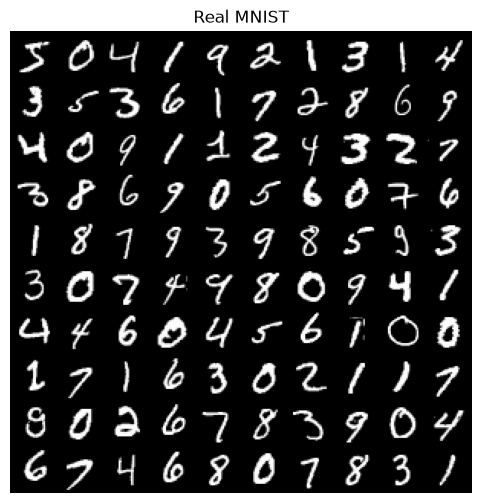

In [7]:
x_mnist, y_mnist = load_data('mnist')
xt_mnist, yt_mnist = load_data('mnist', train=False)
clf_mnist = train_classifier(x_mnist, y_mnist, xt_mnist, yt_mnist)
print('diversity of real test images', round(diversity(xt_mnist), 2))
show_grid(x_mnist[:100], 'Real MNIST')

epoch 1 step 0 d_loss 1.500 g_loss 0.824 D(x) 0.52 D(G(z)) 0.56
epoch 1 step 200 d_loss 0.377 g_loss 2.685 D(x) 0.86 D(G(z)) 0.17
epoch 1 step 400 d_loss 0.400 g_loss 1.689 D(x) 0.79 D(G(z)) 0.14
epoch 2 step 600 d_loss 0.318 g_loss 2.274 D(x) 0.87 D(G(z)) 0.15
epoch 2 step 800 d_loss 0.298 g_loss 1.980 D(x) 0.78 D(G(z)) 0.02
epoch 3 step 1000 d_loss 0.195 g_loss 2.479 D(x) 0.91 D(G(z)) 0.08
epoch 3 step 1200 d_loss 0.241 g_loss 2.107 D(x) 0.86 D(G(z)) 0.06
epoch 3 step 1400 d_loss 0.278 g_loss 2.660 D(x) 0.87 D(G(z)) 0.10
epoch 4 step 1600 d_loss 0.229 g_loss 3.278 D(x) 0.94 D(G(z)) 0.14
epoch 4 step 1800 d_loss 0.296 g_loss 3.212 D(x) 0.94 D(G(z)) 0.18
epoch 5 step 2000 d_loss 0.312 g_loss 1.727 D(x) 0.84 D(G(z)) 0.09
epoch 5 step 2200 d_loss 0.331 g_loss 2.216 D(x) 0.83 D(G(z)) 0.10


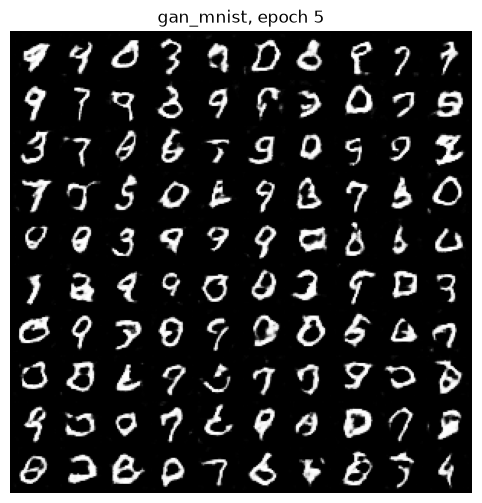

epoch 6 step 2400 d_loss 0.312 g_loss 1.942 D(x) 0.80 D(G(z)) 0.03
epoch 6 step 2600 d_loss 0.256 g_loss 2.317 D(x) 0.86 D(G(z)) 0.07
epoch 6 step 2800 d_loss 0.543 g_loss 2.168 D(x) 0.88 D(G(z)) 0.28
epoch 7 step 3000 d_loss 0.318 g_loss 2.999 D(x) 0.92 D(G(z)) 0.19
epoch 7 step 3200 d_loss 0.316 g_loss 3.291 D(x) 0.91 D(G(z)) 0.17
epoch 8 step 3400 d_loss 0.544 g_loss 0.965 D(x) 0.67 D(G(z)) 0.03
epoch 8 step 3600 d_loss 0.445 g_loss 1.835 D(x) 0.83 D(G(z)) 0.19
epoch 9 step 3800 d_loss 0.317 g_loss 2.653 D(x) 0.88 D(G(z)) 0.15
epoch 9 step 4000 d_loss 0.344 g_loss 1.920 D(x) 0.82 D(G(z)) 0.11
epoch 9 step 4200 d_loss 0.323 g_loss 2.167 D(x) 0.84 D(G(z)) 0.11
epoch 10 step 4400 d_loss 0.224 g_loss 3.059 D(x) 0.94 D(G(z)) 0.13
epoch 10 step 4600 d_loss 0.307 g_loss 2.930 D(x) 0.90 D(G(z)) 0.15


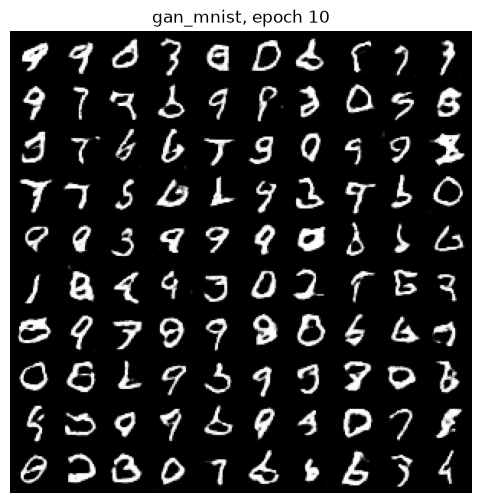

epoch 11 step 4800 d_loss 0.324 g_loss 2.615 D(x) 0.95 D(G(z)) 0.21
epoch 11 step 5000 d_loss 0.321 g_loss 2.777 D(x) 0.90 D(G(z)) 0.17
epoch 12 step 5200 d_loss 0.342 g_loss 2.534 D(x) 0.85 D(G(z)) 0.12
epoch 12 step 5400 d_loss 0.331 g_loss 1.936 D(x) 0.85 D(G(z)) 0.13
epoch 12 step 5600 d_loss 0.312 g_loss 2.326 D(x) 0.87 D(G(z)) 0.13
epoch 13 step 5800 d_loss 0.460 g_loss 1.258 D(x) 0.74 D(G(z)) 0.10
epoch 13 step 6000 d_loss 0.337 g_loss 2.851 D(x) 0.89 D(G(z)) 0.16
epoch 14 step 6200 d_loss 0.227 g_loss 3.225 D(x) 0.92 D(G(z)) 0.12
epoch 14 step 6400 d_loss 0.327 g_loss 2.278 D(x) 0.85 D(G(z)) 0.12
epoch 15 step 6600 d_loss 0.281 g_loss 2.447 D(x) 0.83 D(G(z)) 0.06
epoch 15 step 6800 d_loss 0.356 g_loss 4.214 D(x) 0.97 D(G(z)) 0.24
epoch 15 step 7000 d_loss 0.318 g_loss 2.563 D(x) 0.89 D(G(z)) 0.15


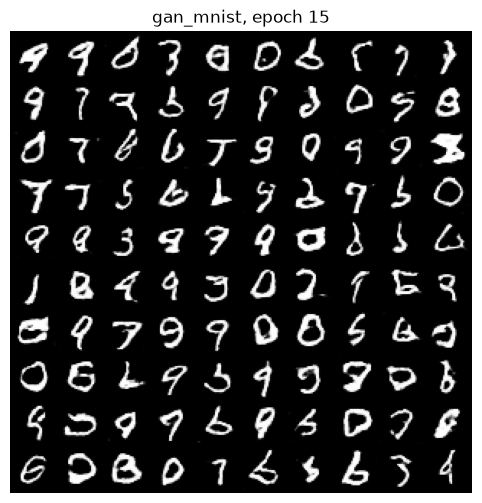

epoch 16 step 7200 d_loss 0.340 g_loss 2.284 D(x) 0.85 D(G(z)) 0.13
epoch 16 step 7400 d_loss 0.539 g_loss 2.756 D(x) 0.90 D(G(z)) 0.30
epoch 17 step 7600 d_loss 0.296 g_loss 2.813 D(x) 0.90 D(G(z)) 0.15
epoch 17 step 7800 d_loss 0.239 g_loss 3.497 D(x) 0.92 D(G(z)) 0.13
epoch 18 step 8000 d_loss 0.310 g_loss 3.092 D(x) 0.93 D(G(z)) 0.18
epoch 18 step 8200 d_loss 0.386 g_loss 1.549 D(x) 0.77 D(G(z)) 0.04
epoch 18 step 8400 d_loss 0.415 g_loss 3.180 D(x) 0.95 D(G(z)) 0.26
epoch 19 step 8600 d_loss 0.302 g_loss 3.265 D(x) 0.91 D(G(z)) 0.15
epoch 19 step 8800 d_loss 0.361 g_loss 2.270 D(x) 0.81 D(G(z)) 0.09
epoch 20 step 9000 d_loss 0.384 g_loss 2.063 D(x) 0.80 D(G(z)) 0.10
epoch 20 step 9200 d_loss 0.297 g_loss 3.421 D(x) 0.95 D(G(z)) 0.19


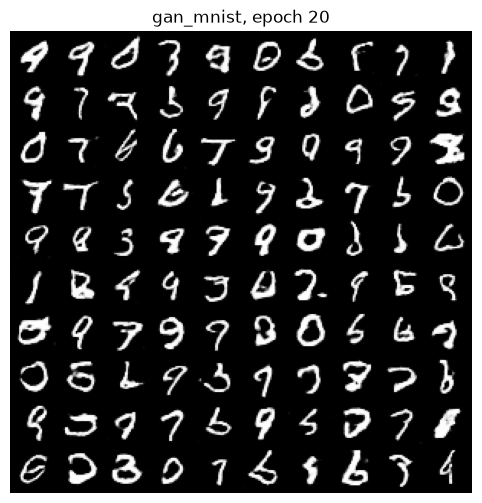

In [8]:
G_mnist = Generator().to(device)
D_mnist = Discriminator().to(device)
hist_mnist = train_gan(G_mnist, D_mnist, x_mnist, y_mnist, GAN_EPOCHS, 'gan_mnist')

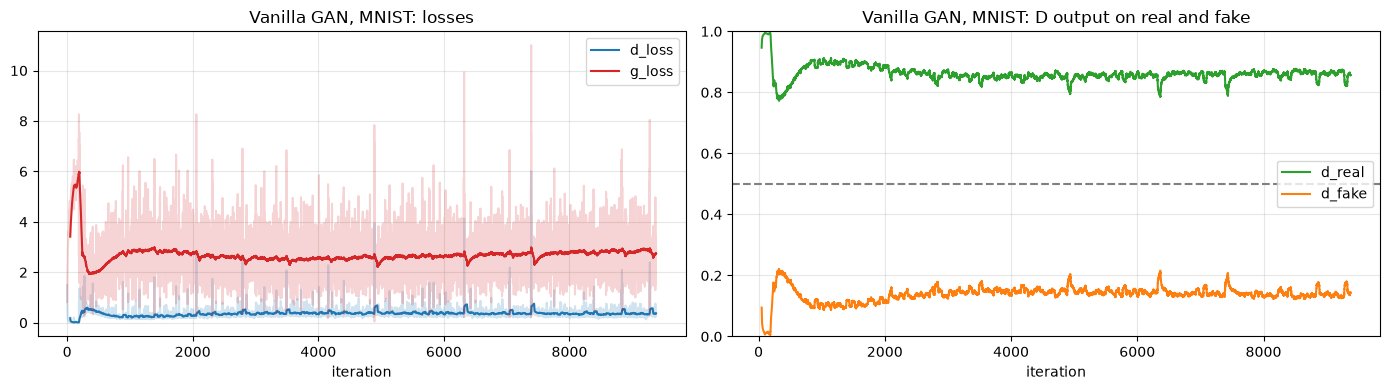

{'confidence': 0.84, 'diversity': 20.189}


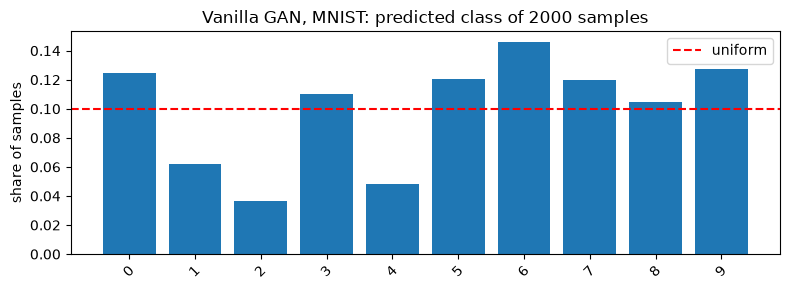

In [9]:
plot_history(hist_mnist, 'Vanilla GAN, MNIST')
stats_mnist = eval_samples(G_mnist, clf_mnist)
print({k: round(v, 3) for k, v in stats_mnist.items() if k != 'class_hist'})
plot_class_hist(stats_mnist, 'Vanilla GAN, MNIST: predicted class of 2000 samples', CLASSES['mnist'])

### Fashion-MNIST

100.0%
100.0%
100.0%
100.0%


classifier test accuracy 0.825
diversity of real test images 22.78


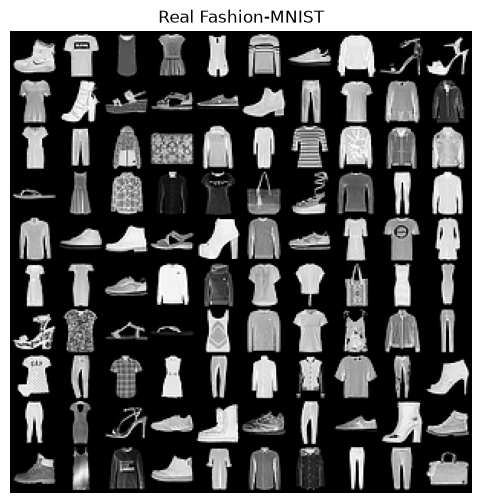

In [10]:
x_fashion, y_fashion = load_data('fashion')
xt_fashion, yt_fashion = load_data('fashion', train=False)
clf_fashion = train_classifier(x_fashion, y_fashion, xt_fashion, yt_fashion)
print('diversity of real test images', round(diversity(xt_fashion), 2))
show_grid(x_fashion[:100], 'Real Fashion-MNIST')

epoch 1 step 0 d_loss 1.404 g_loss 0.823 D(x) 0.59 D(G(z)) 0.57
epoch 1 step 200 d_loss 0.538 g_loss 4.512 D(x) 0.96 D(G(z)) 0.37
epoch 1 step 400 d_loss 0.248 g_loss 2.558 D(x) 0.89 D(G(z)) 0.12
epoch 2 step 600 d_loss 0.220 g_loss 3.644 D(x) 0.96 D(G(z)) 0.15
epoch 2 step 800 d_loss 0.263 g_loss 2.526 D(x) 0.86 D(G(z)) 0.08
epoch 3 step 1000 d_loss 0.272 g_loss 2.639 D(x) 0.90 D(G(z)) 0.14
epoch 3 step 1200 d_loss 0.222 g_loss 2.787 D(x) 0.92 D(G(z)) 0.12
epoch 3 step 1400 d_loss 0.305 g_loss 1.800 D(x) 0.82 D(G(z)) 0.09
epoch 4 step 1600 d_loss 0.351 g_loss 2.454 D(x) 0.87 D(G(z)) 0.17
epoch 4 step 1800 d_loss 0.362 g_loss 2.119 D(x) 0.80 D(G(z)) 0.11
epoch 5 step 2000 d_loss 0.464 g_loss 3.150 D(x) 0.93 D(G(z)) 0.30
epoch 5 step 2200 d_loss 0.398 g_loss 2.201 D(x) 0.85 D(G(z)) 0.19


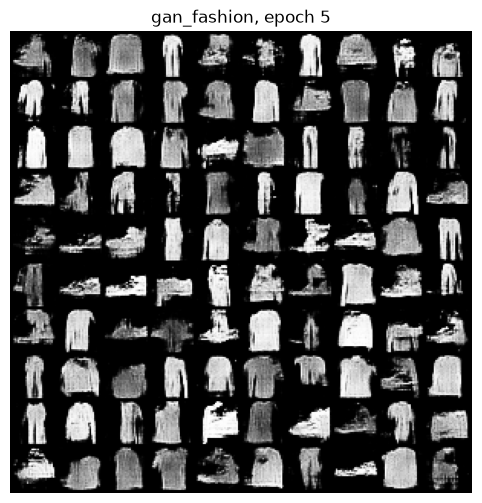

epoch 6 step 2400 d_loss 0.415 g_loss 2.339 D(x) 0.82 D(G(z)) 0.17
epoch 6 step 2600 d_loss 0.526 g_loss 2.794 D(x) 0.88 D(G(z)) 0.28
epoch 6 step 2800 d_loss 0.440 g_loss 2.327 D(x) 0.86 D(G(z)) 0.22
epoch 7 step 3000 d_loss 0.525 g_loss 1.313 D(x) 0.72 D(G(z)) 0.15
epoch 7 step 3200 d_loss 0.430 g_loss 2.260 D(x) 0.78 D(G(z)) 0.11
epoch 8 step 3400 d_loss 0.464 g_loss 2.456 D(x) 0.89 D(G(z)) 0.27
epoch 8 step 3600 d_loss 0.435 g_loss 2.848 D(x) 0.91 D(G(z)) 0.26
epoch 9 step 3800 d_loss 0.474 g_loss 2.359 D(x) 0.84 D(G(z)) 0.22
epoch 9 step 4000 d_loss 0.583 g_loss 1.480 D(x) 0.72 D(G(z)) 0.16
epoch 9 step 4200 d_loss 0.492 g_loss 1.741 D(x) 0.78 D(G(z)) 0.17
epoch 10 step 4400 d_loss 0.941 g_loss 1.048 D(x) 0.52 D(G(z)) 0.08
epoch 10 step 4600 d_loss 0.536 g_loss 2.289 D(x) 0.85 D(G(z)) 0.25


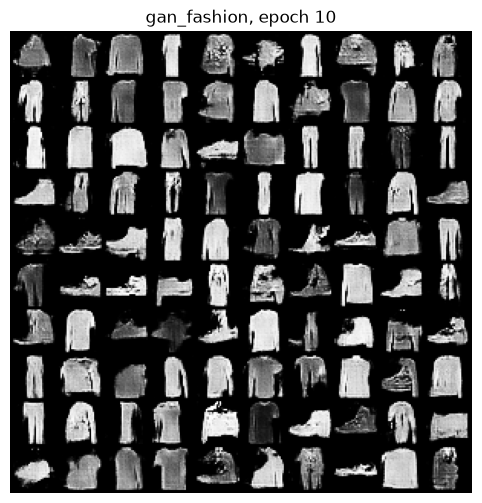

epoch 11 step 4800 d_loss 0.491 g_loss 2.567 D(x) 0.85 D(G(z)) 0.23
epoch 11 step 5000 d_loss 0.455 g_loss 2.051 D(x) 0.88 D(G(z)) 0.24
epoch 12 step 5200 d_loss 0.819 g_loss 4.198 D(x) 0.95 D(G(z)) 0.47
epoch 12 step 5400 d_loss 0.679 g_loss 1.239 D(x) 0.61 D(G(z)) 0.07
epoch 12 step 5600 d_loss 0.505 g_loss 3.097 D(x) 0.93 D(G(z)) 0.32
epoch 13 step 5800 d_loss 0.662 g_loss 1.275 D(x) 0.63 D(G(z)) 0.09
epoch 13 step 6000 d_loss 0.401 g_loss 2.494 D(x) 0.87 D(G(z)) 0.19
epoch 14 step 6200 d_loss 0.427 g_loss 2.186 D(x) 0.83 D(G(z)) 0.18
epoch 14 step 6400 d_loss 0.550 g_loss 1.548 D(x) 0.69 D(G(z)) 0.07
epoch 15 step 6600 d_loss 0.387 g_loss 2.175 D(x) 0.86 D(G(z)) 0.18
epoch 15 step 6800 d_loss 0.430 g_loss 1.734 D(x) 0.79 D(G(z)) 0.14
epoch 15 step 7000 d_loss 0.395 g_loss 2.265 D(x) 0.82 D(G(z)) 0.14


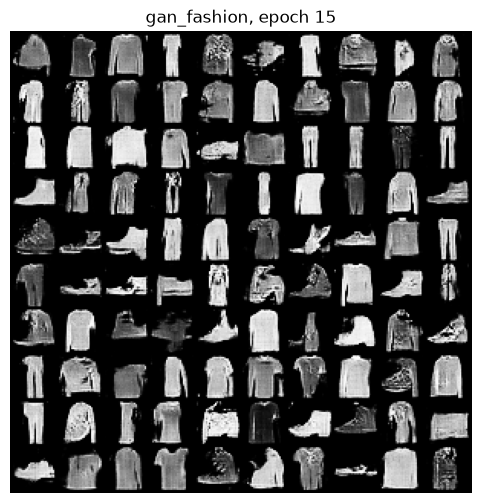

epoch 16 step 7200 d_loss 0.453 g_loss 2.708 D(x) 0.90 D(G(z)) 0.25
epoch 16 step 7400 d_loss 0.662 g_loss 3.638 D(x) 0.96 D(G(z)) 0.42
epoch 17 step 7600 d_loss 0.500 g_loss 1.563 D(x) 0.79 D(G(z)) 0.18
epoch 17 step 7800 d_loss 0.455 g_loss 2.087 D(x) 0.84 D(G(z)) 0.20
epoch 18 step 8000 d_loss 0.355 g_loss 2.315 D(x) 0.83 D(G(z)) 0.11
epoch 18 step 8200 d_loss 0.592 g_loss 1.868 D(x) 0.83 D(G(z)) 0.25
epoch 18 step 8400 d_loss 0.445 g_loss 1.949 D(x) 0.77 D(G(z)) 0.12
epoch 19 step 8600 d_loss 0.554 g_loss 1.846 D(x) 0.77 D(G(z)) 0.18
epoch 19 step 8800 d_loss 0.608 g_loss 3.242 D(x) 0.93 D(G(z)) 0.34
epoch 20 step 9000 d_loss 0.454 g_loss 1.957 D(x) 0.80 D(G(z)) 0.16
epoch 20 step 9200 d_loss 0.281 g_loss 2.862 D(x) 0.86 D(G(z)) 0.10


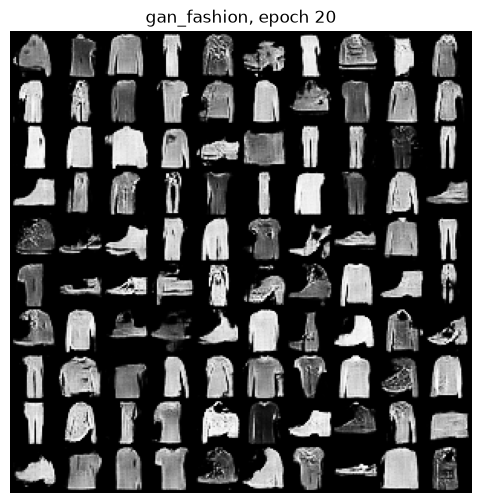

In [11]:
G_fashion = Generator().to(device)
D_fashion = Discriminator().to(device)
hist_fashion = train_gan(G_fashion, D_fashion, x_fashion, y_fashion, GAN_EPOCHS, 'gan_fashion')

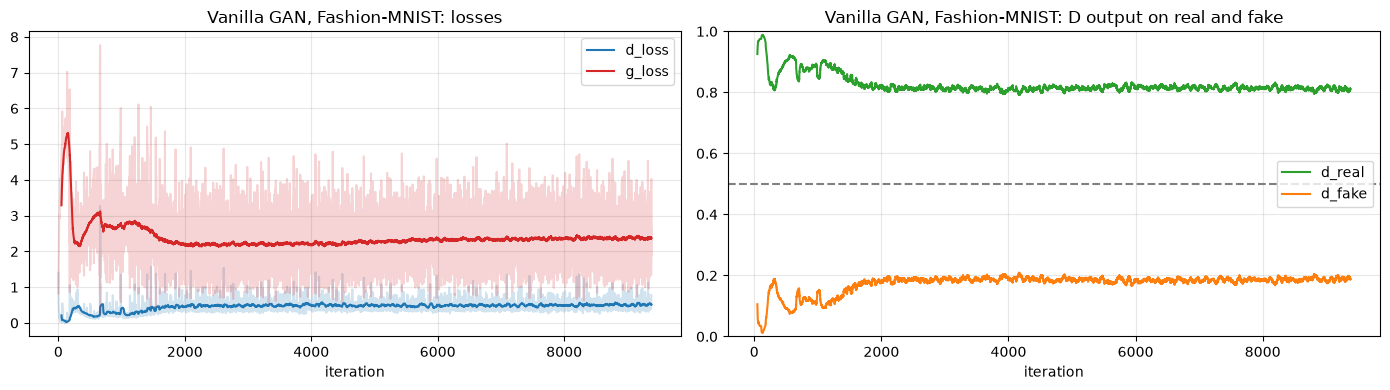

{'confidence': 0.743, 'diversity': 22.607}


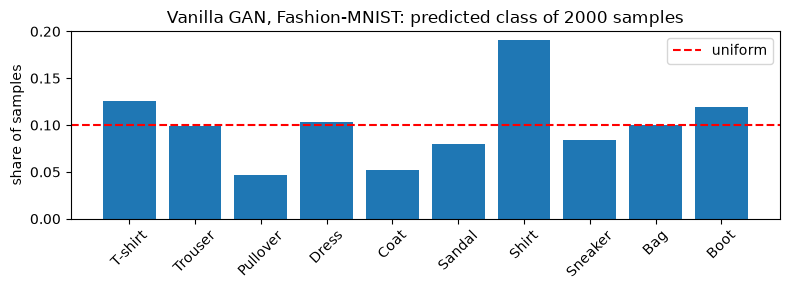

In [12]:
plot_history(hist_fashion, 'Vanilla GAN, Fashion-MNIST')
stats_fashion = eval_samples(G_fashion, clf_fashion)
print({k: round(v, 3) for k, v in stats_fashion.items() if k != 'class_hist'})
plot_class_hist(stats_fashion, 'Vanilla GAN, Fashion-MNIST: predicted class of 2000 samples', CLASSES['fashion'])

## Part 2. Conditional GAN, PatchGAN and feature matching

All three variants are trained on the same dataset with the same settings. Rows of every sample grid are classes 0 to 9.

In [13]:
COND_DATASET = 'mnist'
x_c, y_c = (x_mnist, y_mnist) if COND_DATASET == 'mnist' else (x_fashion, y_fashion)
clf_c = clf_mnist if COND_DATASET == 'mnist' else clf_fashion
cond_runs = {}

def run_cgan(key, patch=False, feature_matching=False):
    G = Generator(n_classes=N_CLASSES).to(device)
    D = Discriminator(n_classes=N_CLASSES, patch=patch).to(device)
    hist = train_gan(G, D, x_c, y_c, GAN_EPOCHS, f'{key}_{COND_DATASET}', conditional=True, feature_matching=feature_matching)
    stats = eval_samples(G, clf_c, conditional=True)
    cond_runs[key] = {'G': G, 'hist': hist, 'stats': stats}
    plot_history(hist, key)
    print({k: round(v, 3) for k, v in stats.items() if k != 'class_hist'})

epoch 1 step 0 d_loss 1.419 g_loss 0.815 D(x) 0.48 D(G(z)) 0.48
epoch 1 step 200 d_loss 0.644 g_loss 1.674 D(x) 0.78 D(G(z)) 0.31
epoch 1 step 400 d_loss 0.679 g_loss 1.234 D(x) 0.62 D(G(z)) 0.12
epoch 2 step 600 d_loss 0.732 g_loss 1.925 D(x) 0.77 D(G(z)) 0.35
epoch 2 step 800 d_loss 0.666 g_loss 1.869 D(x) 0.81 D(G(z)) 0.35
epoch 3 step 1000 d_loss 0.725 g_loss 1.375 D(x) 0.71 D(G(z)) 0.28
epoch 3 step 1200 d_loss 0.655 g_loss 1.493 D(x) 0.72 D(G(z)) 0.24
epoch 3 step 1400 d_loss 0.671 g_loss 1.375 D(x) 0.71 D(G(z)) 0.23
epoch 4 step 1600 d_loss 0.657 g_loss 1.439 D(x) 0.68 D(G(z)) 0.18
epoch 4 step 1800 d_loss 0.819 g_loss 1.856 D(x) 0.81 D(G(z)) 0.42
epoch 5 step 2000 d_loss 0.836 g_loss 1.248 D(x) 0.71 D(G(z)) 0.33
epoch 5 step 2200 d_loss 0.766 g_loss 1.458 D(x) 0.68 D(G(z)) 0.27


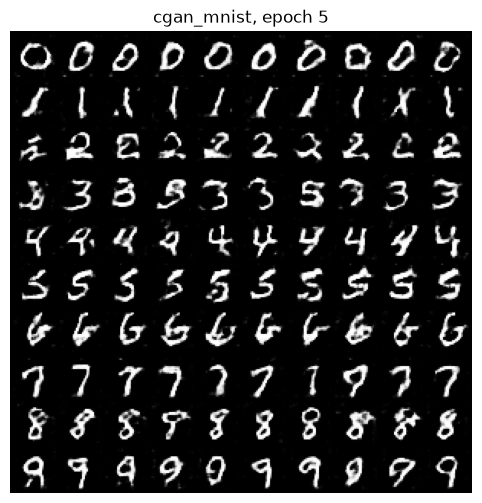

epoch 6 step 2400 d_loss 0.827 g_loss 1.341 D(x) 0.69 D(G(z)) 0.32
epoch 6 step 2600 d_loss 0.860 g_loss 1.207 D(x) 0.62 D(G(z)) 0.27
epoch 6 step 2800 d_loss 0.939 g_loss 1.418 D(x) 0.70 D(G(z)) 0.40
epoch 7 step 3000 d_loss 0.952 g_loss 1.141 D(x) 0.67 D(G(z)) 0.39
epoch 7 step 3200 d_loss 1.000 g_loss 1.992 D(x) 0.77 D(G(z)) 0.48
epoch 8 step 3400 d_loss 1.021 g_loss 1.524 D(x) 0.73 D(G(z)) 0.47
epoch 8 step 3600 d_loss 0.999 g_loss 1.243 D(x) 0.69 D(G(z)) 0.41
epoch 9 step 3800 d_loss 1.029 g_loss 1.347 D(x) 0.72 D(G(z)) 0.47
epoch 9 step 4000 d_loss 0.935 g_loss 1.506 D(x) 0.75 D(G(z)) 0.44
epoch 9 step 4200 d_loss 0.905 g_loss 1.211 D(x) 0.69 D(G(z)) 0.38
epoch 10 step 4400 d_loss 1.152 g_loss 1.593 D(x) 0.76 D(G(z)) 0.54
epoch 10 step 4600 d_loss 1.129 g_loss 0.710 D(x) 0.44 D(G(z)) 0.20


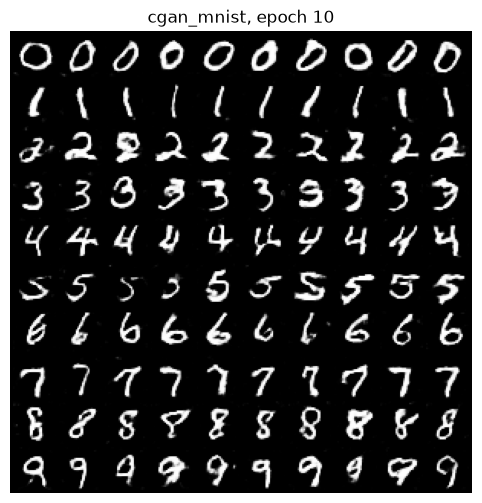

epoch 11 step 4800 d_loss 0.976 g_loss 1.789 D(x) 0.77 D(G(z)) 0.47
epoch 11 step 5000 d_loss 0.958 g_loss 1.093 D(x) 0.60 D(G(z)) 0.30
epoch 12 step 5200 d_loss 1.050 g_loss 1.500 D(x) 0.77 D(G(z)) 0.50
epoch 12 step 5400 d_loss 1.020 g_loss 1.360 D(x) 0.68 D(G(z)) 0.44
epoch 12 step 5600 d_loss 0.960 g_loss 1.147 D(x) 0.65 D(G(z)) 0.37
epoch 13 step 5800 d_loss 1.014 g_loss 2.048 D(x) 0.79 D(G(z)) 0.51
epoch 13 step 6000 d_loss 1.090 g_loss 1.469 D(x) 0.71 D(G(z)) 0.48
epoch 14 step 6200 d_loss 0.925 g_loss 1.446 D(x) 0.73 D(G(z)) 0.42
epoch 14 step 6400 d_loss 0.932 g_loss 1.267 D(x) 0.61 D(G(z)) 0.31
epoch 15 step 6600 d_loss 0.946 g_loss 1.585 D(x) 0.73 D(G(z)) 0.43
epoch 15 step 6800 d_loss 0.942 g_loss 1.226 D(x) 0.66 D(G(z)) 0.38
epoch 15 step 7000 d_loss 1.032 g_loss 1.006 D(x) 0.58 D(G(z)) 0.34


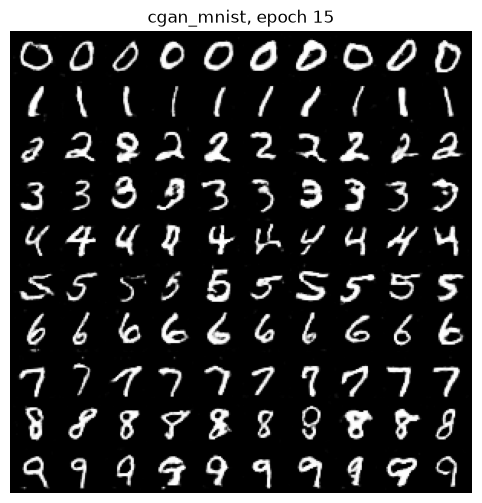

epoch 16 step 7200 d_loss 1.189 g_loss 1.529 D(x) 0.78 D(G(z)) 0.57
epoch 16 step 7400 d_loss 0.983 g_loss 0.904 D(x) 0.51 D(G(z)) 0.22
epoch 17 step 7600 d_loss 0.919 g_loss 1.201 D(x) 0.62 D(G(z)) 0.32
epoch 17 step 7800 d_loss 1.322 g_loss 0.577 D(x) 0.37 D(G(z)) 0.15
epoch 18 step 8000 d_loss 0.941 g_loss 1.480 D(x) 0.76 D(G(z)) 0.45
epoch 18 step 8200 d_loss 1.048 g_loss 1.007 D(x) 0.50 D(G(z)) 0.23
epoch 18 step 8400 d_loss 0.985 g_loss 1.073 D(x) 0.63 D(G(z)) 0.37
epoch 19 step 8600 d_loss 1.227 g_loss 0.595 D(x) 0.41 D(G(z)) 0.19
epoch 19 step 8800 d_loss 1.370 g_loss 2.334 D(x) 0.88 D(G(z)) 0.67
epoch 20 step 9000 d_loss 0.877 g_loss 1.105 D(x) 0.60 D(G(z)) 0.26
epoch 20 step 9200 d_loss 1.033 g_loss 0.958 D(x) 0.62 D(G(z)) 0.36


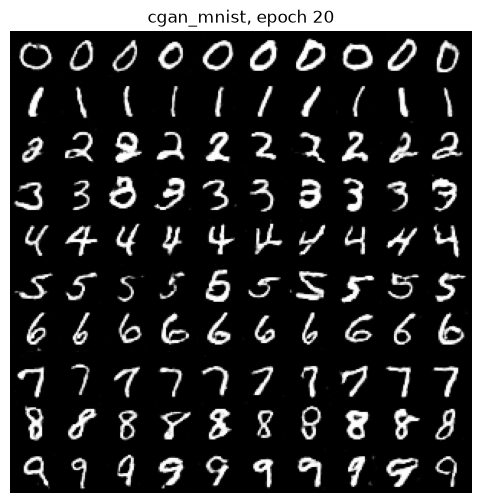

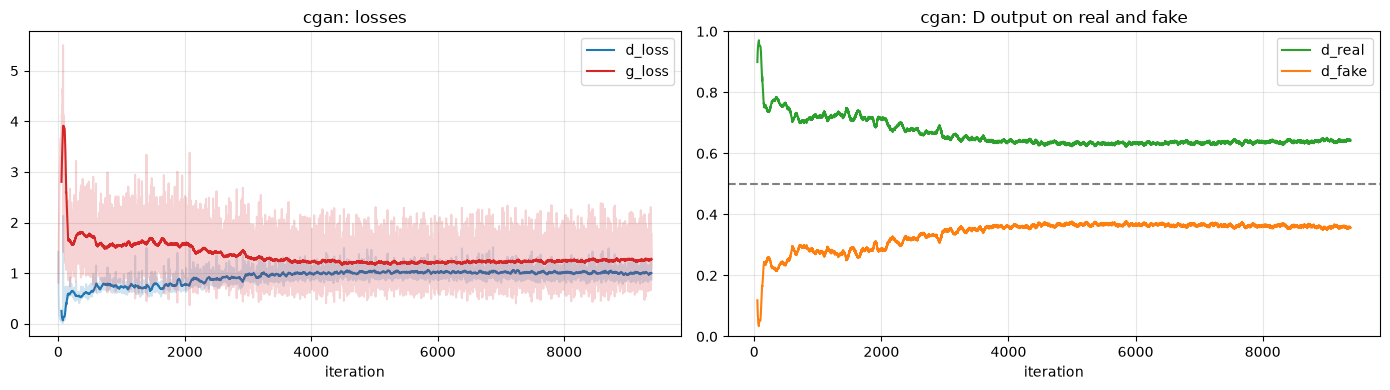

{'confidence': 0.975, 'diversity': 19.983, 'label_acc': 0.985}


In [14]:
run_cgan('cgan')

epoch 1 step 0 d_loss 1.418 g_loss 0.735 D(x) 0.48 D(G(z)) 0.48
epoch 1 step 200 d_loss 1.175 g_loss 0.847 D(x) 0.56 D(G(z)) 0.44
epoch 1 step 400 d_loss 1.226 g_loss 0.810 D(x) 0.54 D(G(z)) 0.45
epoch 2 step 600 d_loss 1.238 g_loss 0.804 D(x) 0.54 D(G(z)) 0.45
epoch 2 step 800 d_loss 1.243 g_loss 0.826 D(x) 0.55 D(G(z)) 0.46
epoch 3 step 1000 d_loss 1.229 g_loss 0.803 D(x) 0.54 D(G(z)) 0.43
epoch 3 step 1200 d_loss 1.229 g_loss 0.830 D(x) 0.55 D(G(z)) 0.44
epoch 3 step 1400 d_loss 1.233 g_loss 0.904 D(x) 0.57 D(G(z)) 0.47
epoch 4 step 1600 d_loss 1.242 g_loss 0.814 D(x) 0.53 D(G(z)) 0.43
epoch 4 step 1800 d_loss 1.238 g_loss 0.795 D(x) 0.54 D(G(z)) 0.44
epoch 5 step 2000 d_loss 1.296 g_loss 0.773 D(x) 0.52 D(G(z)) 0.46
epoch 5 step 2200 d_loss 1.299 g_loss 0.828 D(x) 0.55 D(G(z)) 0.48


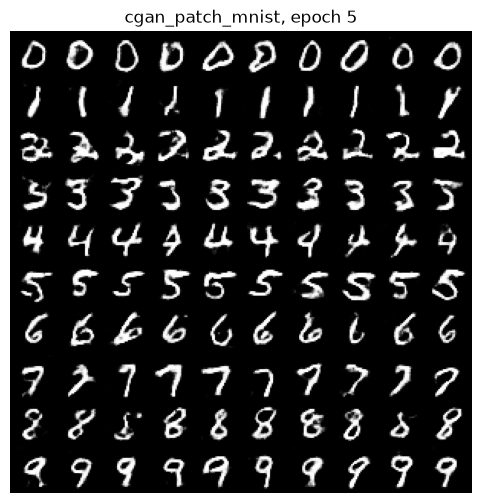

epoch 6 step 2400 d_loss 1.295 g_loss 0.784 D(x) 0.53 D(G(z)) 0.47
epoch 6 step 2600 d_loss 1.291 g_loss 0.772 D(x) 0.52 D(G(z)) 0.46
epoch 6 step 2800 d_loss 1.318 g_loss 0.814 D(x) 0.54 D(G(z)) 0.48
epoch 7 step 3000 d_loss 1.277 g_loss 0.855 D(x) 0.55 D(G(z)) 0.48
epoch 7 step 3200 d_loss 1.316 g_loss 0.745 D(x) 0.52 D(G(z)) 0.46
epoch 8 step 3400 d_loss 1.328 g_loss 0.735 D(x) 0.51 D(G(z)) 0.45
epoch 8 step 3600 d_loss 1.294 g_loss 0.789 D(x) 0.52 D(G(z)) 0.46
epoch 9 step 3800 d_loss 1.302 g_loss 0.790 D(x) 0.53 D(G(z)) 0.46
epoch 9 step 4000 d_loss 1.293 g_loss 0.771 D(x) 0.53 D(G(z)) 0.46
epoch 9 step 4200 d_loss 1.299 g_loss 0.779 D(x) 0.53 D(G(z)) 0.47
epoch 10 step 4400 d_loss 1.296 g_loss 0.792 D(x) 0.54 D(G(z)) 0.48
epoch 10 step 4600 d_loss 1.301 g_loss 0.798 D(x) 0.53 D(G(z)) 0.47


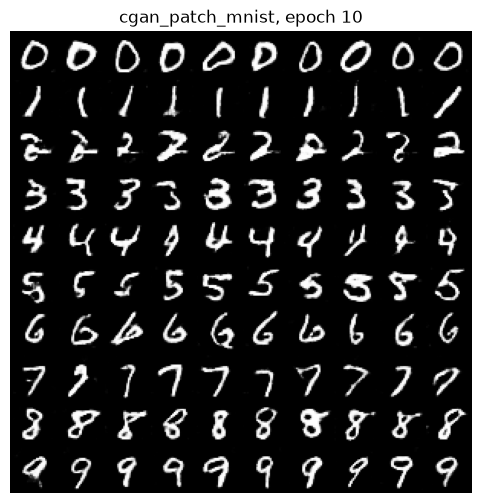

epoch 11 step 4800 d_loss 1.289 g_loss 0.817 D(x) 0.54 D(G(z)) 0.47
epoch 11 step 5000 d_loss 1.313 g_loss 0.824 D(x) 0.54 D(G(z)) 0.48
epoch 12 step 5200 d_loss 1.324 g_loss 0.748 D(x) 0.52 D(G(z)) 0.46
epoch 12 step 5400 d_loss 1.341 g_loss 0.832 D(x) 0.55 D(G(z)) 0.50
epoch 12 step 5600 d_loss 1.291 g_loss 0.801 D(x) 0.55 D(G(z)) 0.48
epoch 13 step 5800 d_loss 1.306 g_loss 0.747 D(x) 0.52 D(G(z)) 0.46
epoch 13 step 6000 d_loss 1.329 g_loss 0.807 D(x) 0.53 D(G(z)) 0.48
epoch 14 step 6200 d_loss 1.296 g_loss 0.827 D(x) 0.54 D(G(z)) 0.48
epoch 14 step 6400 d_loss 1.328 g_loss 0.874 D(x) 0.56 D(G(z)) 0.50
epoch 15 step 6600 d_loss 1.306 g_loss 0.789 D(x) 0.53 D(G(z)) 0.47
epoch 15 step 6800 d_loss 1.286 g_loss 0.774 D(x) 0.52 D(G(z)) 0.45
epoch 15 step 7000 d_loss 1.284 g_loss 0.767 D(x) 0.52 D(G(z)) 0.45


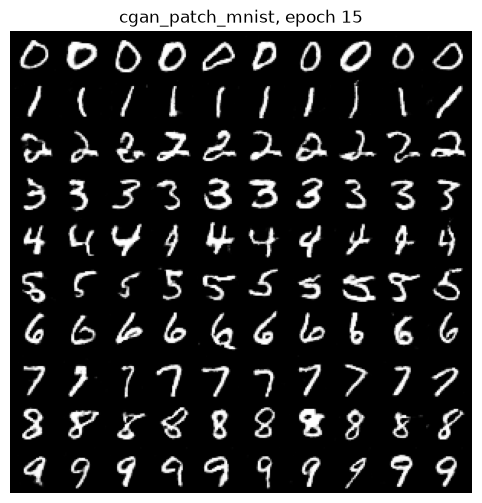

epoch 16 step 7200 d_loss 1.299 g_loss 0.763 D(x) 0.51 D(G(z)) 0.45
epoch 16 step 7400 d_loss 1.305 g_loss 0.778 D(x) 0.52 D(G(z)) 0.46
epoch 17 step 7600 d_loss 1.311 g_loss 0.824 D(x) 0.54 D(G(z)) 0.48
epoch 17 step 7800 d_loss 1.308 g_loss 0.864 D(x) 0.55 D(G(z)) 0.48
epoch 18 step 8000 d_loss 1.308 g_loss 0.762 D(x) 0.51 D(G(z)) 0.45
epoch 18 step 8200 d_loss 1.315 g_loss 0.768 D(x) 0.52 D(G(z)) 0.46
epoch 18 step 8400 d_loss 1.298 g_loss 0.838 D(x) 0.54 D(G(z)) 0.48
epoch 19 step 8600 d_loss 1.293 g_loss 0.828 D(x) 0.54 D(G(z)) 0.47
epoch 19 step 8800 d_loss 1.272 g_loss 0.836 D(x) 0.54 D(G(z)) 0.46
epoch 20 step 9000 d_loss 1.327 g_loss 0.802 D(x) 0.54 D(G(z)) 0.48
epoch 20 step 9200 d_loss 1.334 g_loss 0.767 D(x) 0.51 D(G(z)) 0.45


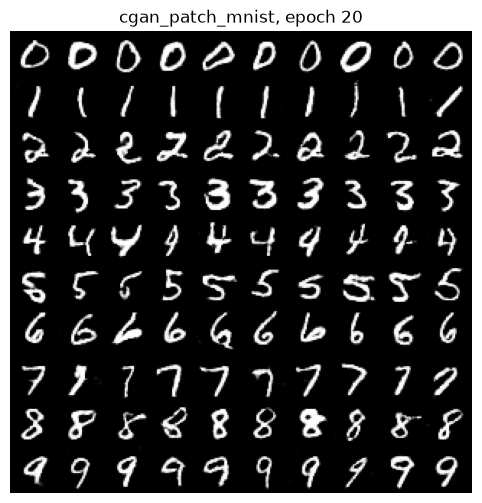

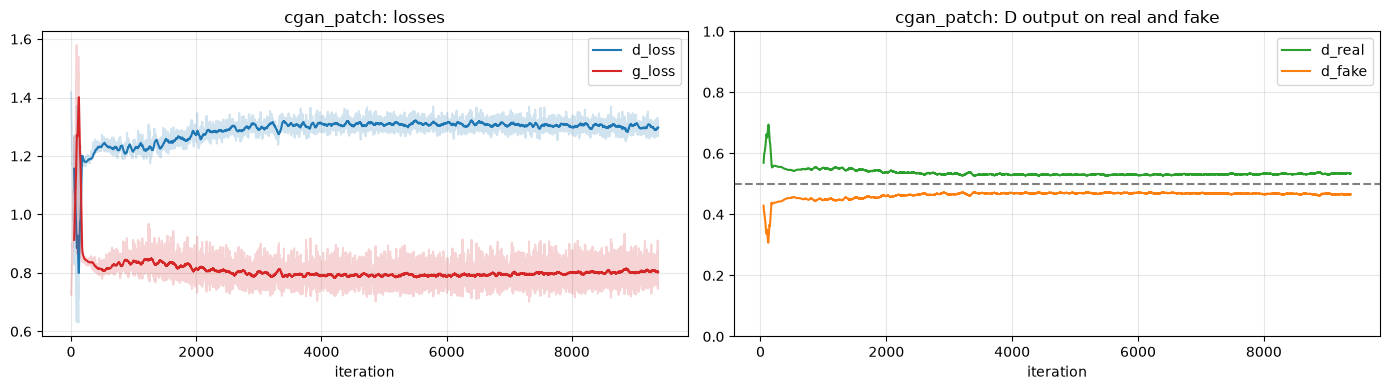

{'confidence': 0.973, 'diversity': 20.095, 'label_acc': 0.979}


In [15]:
run_cgan('cgan_patch', patch=True)

epoch 1 step 0 d_loss 1.445 g_loss 0.052 D(x) 0.47 D(G(z)) 0.48
epoch 1 step 200 d_loss 0.290 g_loss 0.007 D(x) 0.80 D(G(z)) 0.06
epoch 1 step 400 d_loss 0.220 g_loss 0.006 D(x) 0.89 D(G(z)) 0.09
epoch 2 step 600 d_loss 0.279 g_loss 0.004 D(x) 0.89 D(G(z)) 0.13
epoch 2 step 800 d_loss 0.323 g_loss 0.005 D(x) 0.80 D(G(z)) 0.08
epoch 3 step 1000 d_loss 0.254 g_loss 0.004 D(x) 0.84 D(G(z)) 0.07
epoch 3 step 1200 d_loss 0.274 g_loss 0.004 D(x) 0.94 D(G(z)) 0.18
epoch 3 step 1400 d_loss 0.216 g_loss 0.005 D(x) 0.90 D(G(z)) 0.09
epoch 4 step 1600 d_loss 0.158 g_loss 0.005 D(x) 0.93 D(G(z)) 0.07
epoch 4 step 1800 d_loss 0.156 g_loss 0.005 D(x) 0.93 D(G(z)) 0.07
epoch 5 step 2000 d_loss 0.136 g_loss 0.005 D(x) 0.92 D(G(z)) 0.05
epoch 5 step 2200 d_loss 0.147 g_loss 0.004 D(x) 0.91 D(G(z)) 0.05


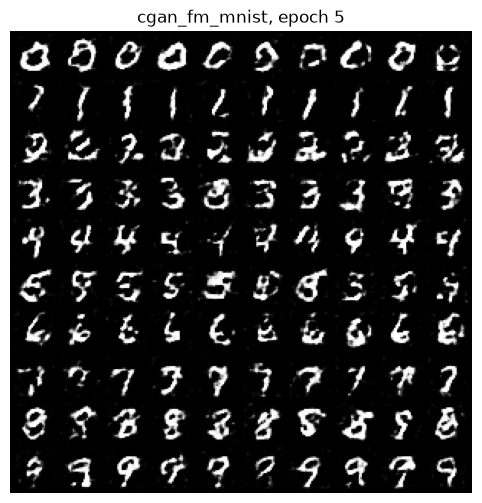

epoch 6 step 2400 d_loss 0.150 g_loss 0.004 D(x) 0.95 D(G(z)) 0.09
epoch 6 step 2600 d_loss 0.165 g_loss 0.004 D(x) 0.89 D(G(z)) 0.04
epoch 6 step 2800 d_loss 0.129 g_loss 0.005 D(x) 0.94 D(G(z)) 0.06
epoch 7 step 3000 d_loss 0.136 g_loss 0.004 D(x) 0.90 D(G(z)) 0.02
epoch 7 step 3200 d_loss 0.198 g_loss 0.004 D(x) 0.86 D(G(z)) 0.04
epoch 8 step 3400 d_loss 0.133 g_loss 0.005 D(x) 0.95 D(G(z)) 0.07
epoch 8 step 3600 d_loss 0.134 g_loss 0.004 D(x) 0.92 D(G(z)) 0.04
epoch 9 step 3800 d_loss 0.108 g_loss 0.004 D(x) 0.95 D(G(z)) 0.05
epoch 9 step 4000 d_loss 0.115 g_loss 0.004 D(x) 0.95 D(G(z)) 0.06
epoch 9 step 4200 d_loss 0.100 g_loss 0.004 D(x) 0.94 D(G(z)) 0.03
epoch 10 step 4400 d_loss 0.131 g_loss 0.004 D(x) 0.94 D(G(z)) 0.06
epoch 10 step 4600 d_loss 0.628 g_loss 0.003 D(x) 0.94 D(G(z)) 0.29


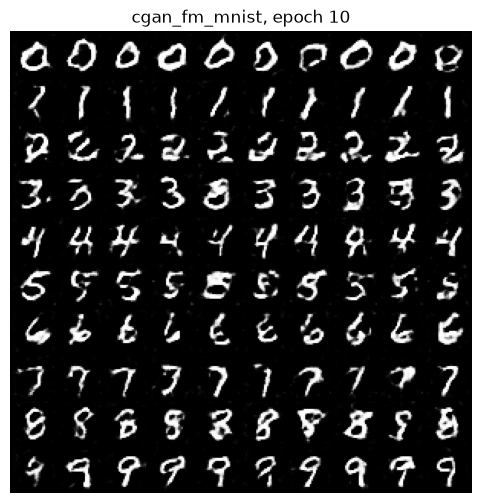

epoch 11 step 4800 d_loss 0.186 g_loss 0.004 D(x) 0.97 D(G(z)) 0.12
epoch 11 step 5000 d_loss 0.132 g_loss 0.005 D(x) 0.94 D(G(z)) 0.06
epoch 12 step 5200 d_loss 0.144 g_loss 0.004 D(x) 0.93 D(G(z)) 0.06
epoch 12 step 5400 d_loss 0.128 g_loss 0.004 D(x) 0.94 D(G(z)) 0.06
epoch 12 step 5600 d_loss 0.105 g_loss 0.004 D(x) 0.93 D(G(z)) 0.03
epoch 13 step 5800 d_loss 0.177 g_loss 0.004 D(x) 0.96 D(G(z)) 0.11
epoch 13 step 6000 d_loss 0.085 g_loss 0.005 D(x) 0.97 D(G(z)) 0.05
epoch 14 step 6200 d_loss 0.164 g_loss 0.005 D(x) 0.91 D(G(z)) 0.04
epoch 14 step 6400 d_loss 0.214 g_loss 0.004 D(x) 0.85 D(G(z)) 0.02
epoch 15 step 6600 d_loss 0.128 g_loss 0.004 D(x) 0.96 D(G(z)) 0.07
epoch 15 step 6800 d_loss 0.168 g_loss 0.004 D(x) 0.97 D(G(z)) 0.12
epoch 15 step 7000 d_loss 0.104 g_loss 0.005 D(x) 0.96 D(G(z)) 0.06


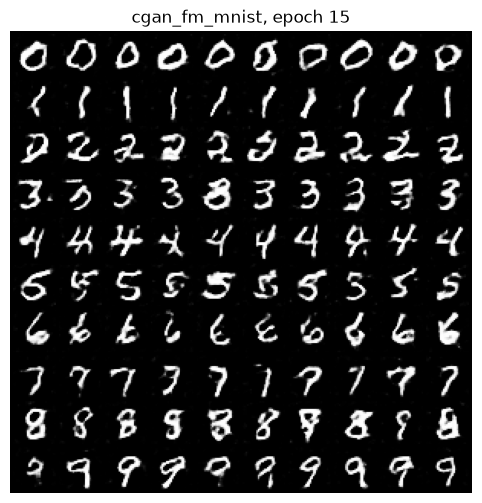

epoch 16 step 7200 d_loss 0.336 g_loss 0.004 D(x) 0.91 D(G(z)) 0.16
epoch 16 step 7400 d_loss 0.121 g_loss 0.004 D(x) 0.91 D(G(z)) 0.02
epoch 17 step 7600 d_loss 0.135 g_loss 0.004 D(x) 0.94 D(G(z)) 0.07
epoch 17 step 7800 d_loss 0.132 g_loss 0.004 D(x) 0.98 D(G(z)) 0.10
epoch 18 step 8000 d_loss 0.118 g_loss 0.004 D(x) 0.92 D(G(z)) 0.03
epoch 18 step 8200 d_loss 0.090 g_loss 0.004 D(x) 0.97 D(G(z)) 0.05
epoch 18 step 8400 d_loss 0.089 g_loss 0.004 D(x) 0.98 D(G(z)) 0.06
epoch 19 step 8600 d_loss 0.095 g_loss 0.004 D(x) 0.96 D(G(z)) 0.05
epoch 19 step 8800 d_loss 0.134 g_loss 0.004 D(x) 0.93 D(G(z)) 0.05
epoch 20 step 9000 d_loss 0.135 g_loss 0.004 D(x) 0.94 D(G(z)) 0.06
epoch 20 step 9200 d_loss 0.142 g_loss 0.004 D(x) 0.91 D(G(z)) 0.04


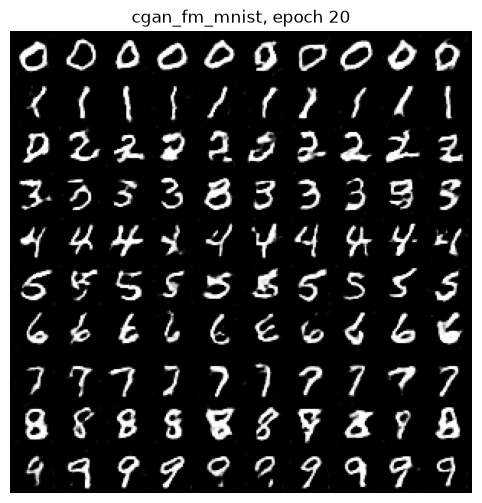

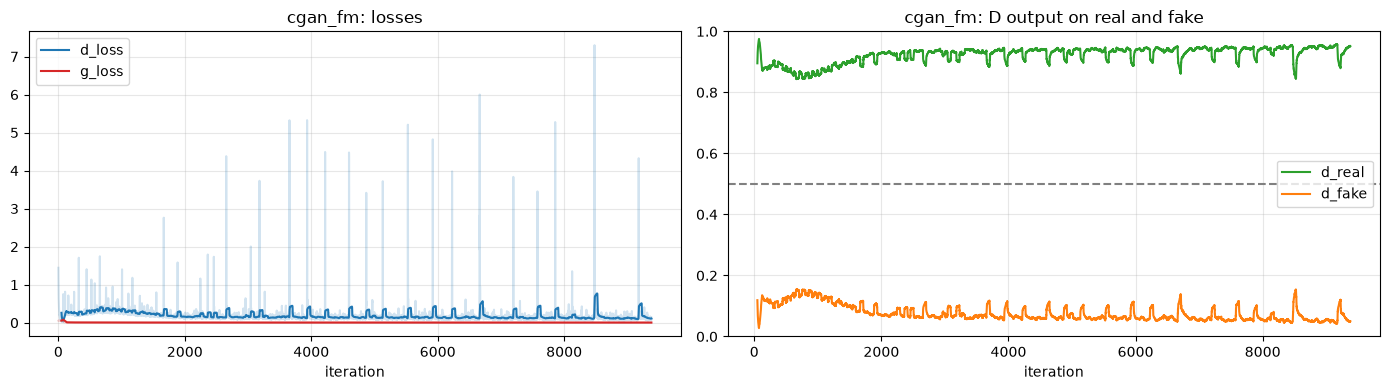

{'confidence': 0.965, 'diversity': 20.265, 'label_acc': 0.969}


In [16]:
run_cgan('cgan_fm', feature_matching=True)

                label acc  confidence  diversity
cgan                0.985       0.975      19.98
cgan_patch          0.979       0.973      20.09
cgan_fm             0.969       0.965      20.27


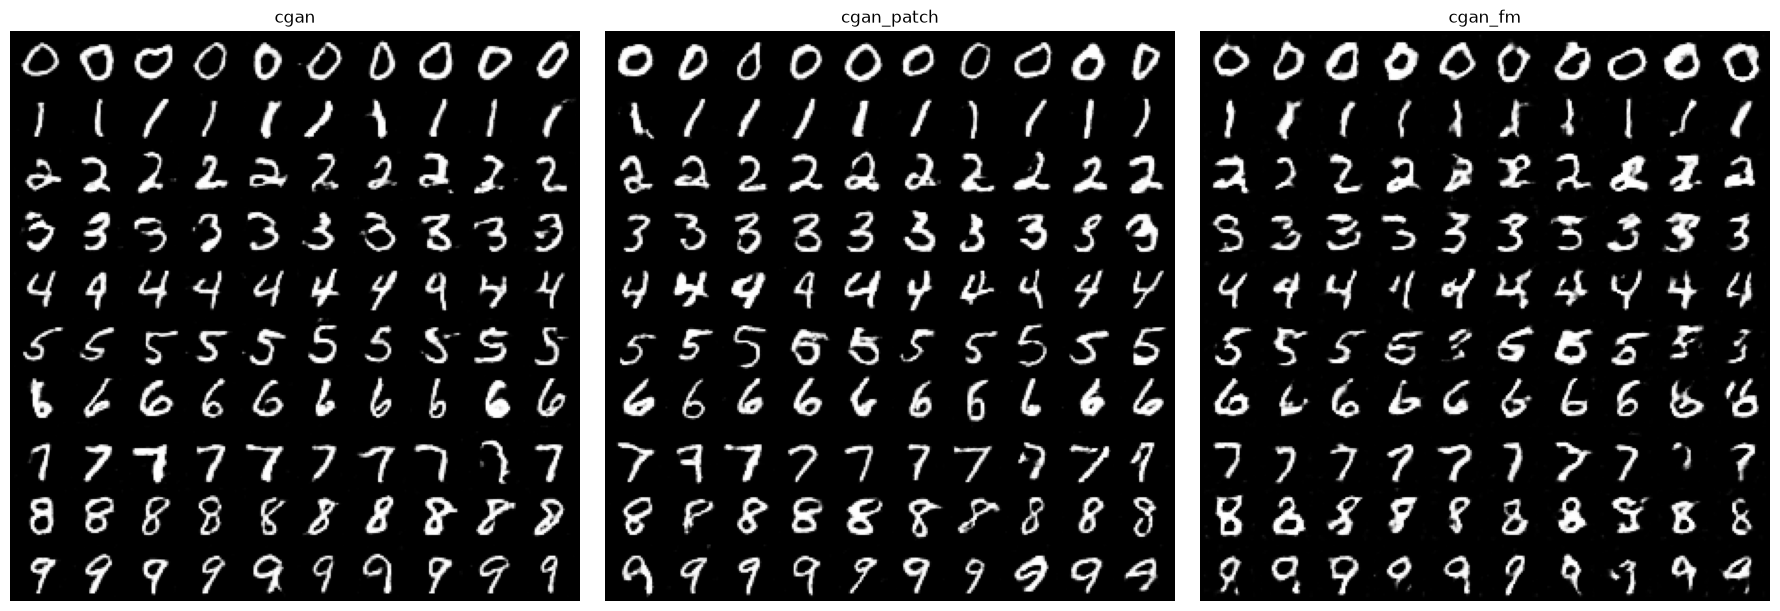

In [17]:
print(f'{"":14}{"label acc":>11}{"confidence":>12}{"diversity":>11}')
for key, r in cond_runs.items():
    s = r['stats']
    print(f'{key:14}{s["label_acc"]:11.3f}{s["confidence"]:12.3f}{s["diversity"]:11.2f}')
with open(f'cond_stats_{COND_DATASET}.json', 'w') as f:
    json.dump({k: r['stats'] for k, r in cond_runs.items()}, f)
torch.manual_seed(0)
z = torch.randn(100, NOISE_DIM, device=device)
y = torch.arange(N_CLASSES, device=device).repeat_interleave(10)
plt.figure(figsize=(18, 6))
for i, (key, r) in enumerate(cond_runs.items()):
    r['G'].eval()
    with torch.no_grad():
        imgs = r['G'](z, y)
    plt.subplot(1, len(cond_runs), i + 1)
    plt.imshow(vutils.make_grid(to_img(imgs).cpu(), nrow=10, padding=2).permute(1, 2, 0))
    plt.title(key)
    plt.axis('off')
plt.tight_layout()
plt.show()